# Q2C | Analyze Relationships Between Attributes

**Class:** CS P556 - Applied Machine Learning  
**Student:** Reed Turgeon

**Disclosure:** This notebook was completed with the assistance of Claude Code (Opus 5.5) and the book *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd edition) by Aurélien Géron.

> C. Analyze the relationships between the data attributes, and between the data attributes and label. This involves computing the Pearson Correlation Coefficient (PCC) and generating scatter plots.

**IMPORTANT**

This dataset has no train / test split of its own, so the same chronological split as Q2B is made at the top of this notebook: the earliest 584 days are train and the latest 147 days are test. Every statistic and every score below is computed on the training rows only, so no analysis or treatment decision is influenced by the test data (data snooping).

# Answer Summary

**PCC and scatter plots** (train rows only: 584 rows, 2011-01-01 to 2012-08-06)
- A scatter matrix of the 4 continuous attributes (`Temp`, `FeelsLike`, `Humidity`, `Wind`) and `Rentals`, with each column's distribution curve on the diagonal. A correlation matrix of all 11 attributes and `Rentals`, with Pearson r (PCC) in the lower triangle and Spearman rho in the upper. A collinearity table (the attribute pairs with Pearson r of 0.3 or more in size, next to each attribute's r with `Rentals`) and an R2 Gain table over the continuous and binary attributes (the pairs that gain 0.01 or more in R² over the better of their two attributes alone).

**Attributes and label**
- Strength: `FeelsLike`, `Temp` and `Year` have the strongest Pearson r with `Rentals`, all moderate, led by `FeelsLike` (0.69). `Weather`, `Season`, `Month`, `Wind` and `Humidity` are weak, and `IsHoliday`, `IsWorkday` and `Weekday` show none.
- Shape: in the scatter matrix, `Rentals` rise with temperature and level off at the warm end, while `Humidity` and `Wind` against `Rentals` are wide clouds. Pearson and Spearman agree within 0.02 on all 4 continuous attributes, and neither shows the leveling off.
- Warm days split in two: in the scatter matrix, warm days form a lower and an upper `Rentals` band that temperature alone cannot tell apart.
- Codes can understate an attribute: for `Season`, `Month`, `Weekday` and `Weather`, r reads only a straight line across the code numbers, so a code whose `Rentals` rise and then fall gets a small r even when its levels differ a lot (ex `Month`, r 0.20).

**Attribute vs attribute**
- Three pairs stand out: `Temp` / `FeelsLike`, `Season` / `Month` and `Humidity` / `Weather`. Every other pair's Pearson r is 0.46 or less in size.
- `Temp` and `FeelsLike` carry the same information: their pair gains less than 0.01 R², so it is not shown.
- Calendar and temperature move together: `Season` and `Month` rise with `Temp` and `FeelsLike` (0.38 to 0.46).
- `Year` falls with `Season` and `Month` because of where train stops (2012-08-06): the second year's train rows end in early August, so its later seasons and months are missing.
- `Year` adds the most: nearly unrelated to temperature, it adds +0.242 R² on top of `Temp` and +0.241 on top of `FeelsLike`, far more than any other pair.
- Small additions: `Humidity` adds a little on top of temperature (+0.048 to `FeelsLike`). `Wind` adds less than 0.01 to temperature alone.
- No additions: `IsHoliday` and `IsWorkday` reach the 0.01 bar in no pair.

**Carried to D**
- One of `Temp` and `FeelsLike` is enough: they are near duplicates (r 0.997).
- Keep `FeelsLike`, drop `Temp`: `FeelsLike`'s r with `Rentals` is a hair higher (0.690 against 0.685).

---

# Imports

In [1]:
import pandas as pd

import Q2.consts as Q2_CONSTS
from consts import TEST_SIZE, COLLINEARITY_MIN_R, R2_GAIN_MARGIN

from utils import (
	read_csv_to_df,
	SPLIT,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
df = read_csv_to_df(path=Q2_CONSTS.DATA_PATH, parse_dates=["dteday"])
df = df.rename(columns=Q2_CONSTS.SHORT_NAMES)

# Train / Test Split

In [3]:
train_df, test_df = SPLIT.chronological_split(df=df, date_col="Date", test_size=TEST_SIZE)

pd.DataFrame({
	"rows": [len(train_df), len(test_df)],
	"% of rows": [round(len(train_df) / len(df) * 100, 2), round(len(test_df) / len(df) * 100, 2)],
	"first date": [f"{train_df['Date'].min():%Y-%m-%d}", f"{test_df['Date'].min():%Y-%m-%d}"],
	"last date": [f"{train_df['Date'].max():%Y-%m-%d}", f"{test_df['Date'].max():%Y-%m-%d}"],
}, index=["train", "test"])

,rows,% of rows,first date,last date
train,584,79.89,2011-01-01,2012-08-06
test,147,20.11,2012-08-07,2012-12-31


# Attribute Groups

In [4]:
BINARY = ["Year", "IsHoliday", "IsWorkday"]
MULTI_LEVEL = ["Season", "Month", "Weekday", "Weather"]

ATTRIBUTES = Q2_CONSTS.CONTINUOUS + BINARY + MULTI_LEVEL

print(f"{len(ATTRIBUTES)} attributes: {', '.join(ATTRIBUTES)}")
print(f"left out: {', '.join(col for col in train_df.columns if col not in ATTRIBUTES + [Q2_CONSTS.TARGET])}")

11 attributes: Temp, FeelsLike, Humidity, Wind, Year, IsHoliday, IsWorkday, Season, Month, Weekday, Weather
left out: ID, Date, Casual, Registered


# Attribute vs Attribute and Label

## Scatter Matrix

Only the 4 continuous attributes are plotted: the coded attributes would show as stacked vertical lines, so their relationship with `Rentals` is read through r here and through the box plots per level in Q2B.

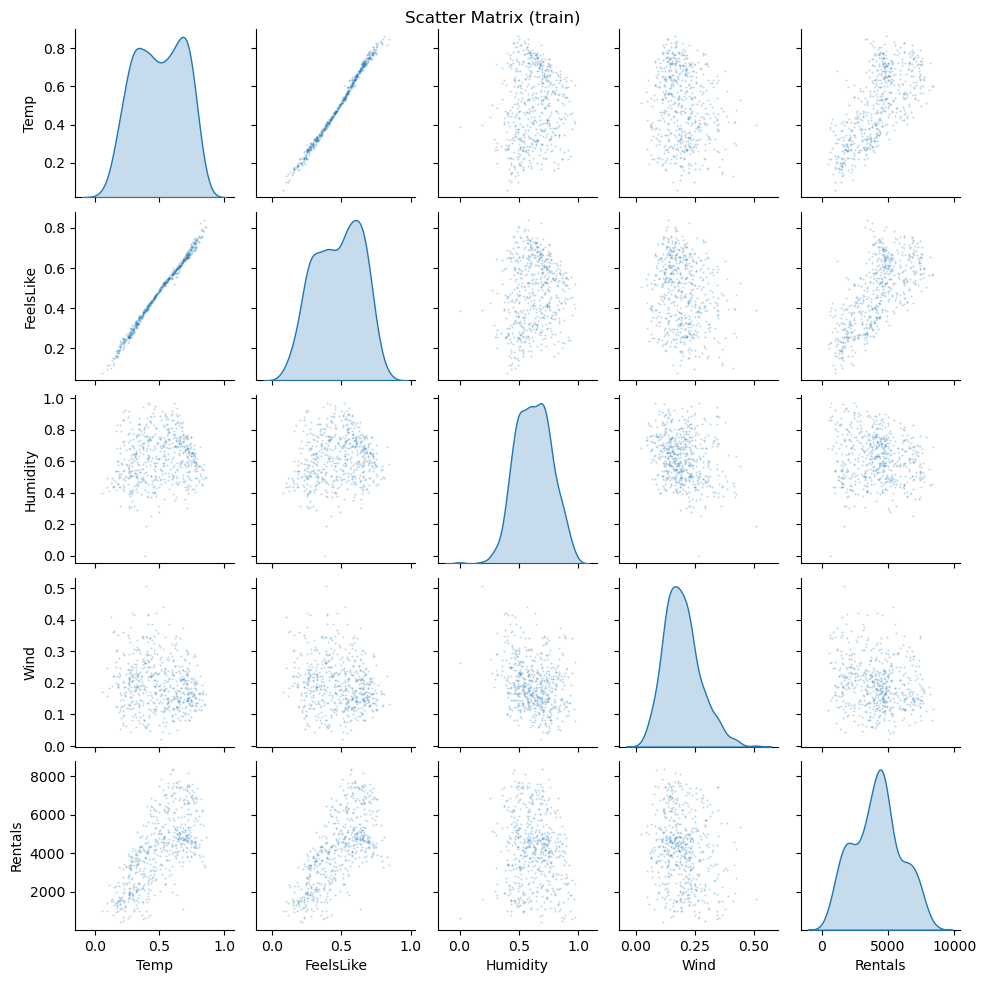

In [5]:
PLOTTING.scatter_matrix(df=train_df[Q2_CONSTS.CONTINUOUS + [Q2_CONSTS.TARGET]], title='Scatter Matrix (train)');

### Notes / Observations

- One line, not two attributes: `Temp` against `FeelsLike` is a thin straight band across the whole range, so the two carry the same information about every day.
- Temperature is the only clear trend with `Rentals`: the cloud rises with `Temp` and `FeelsLike` and levels off at the warm end. `Humidity` and `Wind` against `Rentals` are wide clouds with at most a slight downward tilt.
- Warm days split in two: at the warm end of `Temp` and `FeelsLike`, `Rentals` form a lower band (about 4,000 to 5,000) and an upper band at the same temperature. Temperature cannot tell them apart, so a line on temperature alone over-predicts the lower band and under-predicts the upper one.
- The weather measurements barely move together: `Humidity`, `Wind` and temperature form round clouds against each other, with at most a weak tilt (`Humidity` against `Wind`, r -0.26 in the correlation matrix), so each brings its own information.

## Correlation

> How To Read

- **Strength bands** used in the notes, by the size of r (sign ignored), following Schober, Boer and Schwarte (2018): strong 0.7 or more, moderate 0.4 to 0.7, weak 0.1 to 0.4, none below 0.1.
- **r and R²:** r is the Pearson correlation, from -1 to 1, and its sign gives the direction. R² (in the R2 Gain table) is the share of `Rentals`'s variance a fit explains, from 0 to 1, with no sign. For a single straight line, R² is r squared.

<Axes: title={'center': 'Pearson (lower) vs Spearman (upper) Correlation Matrix (train)'}>

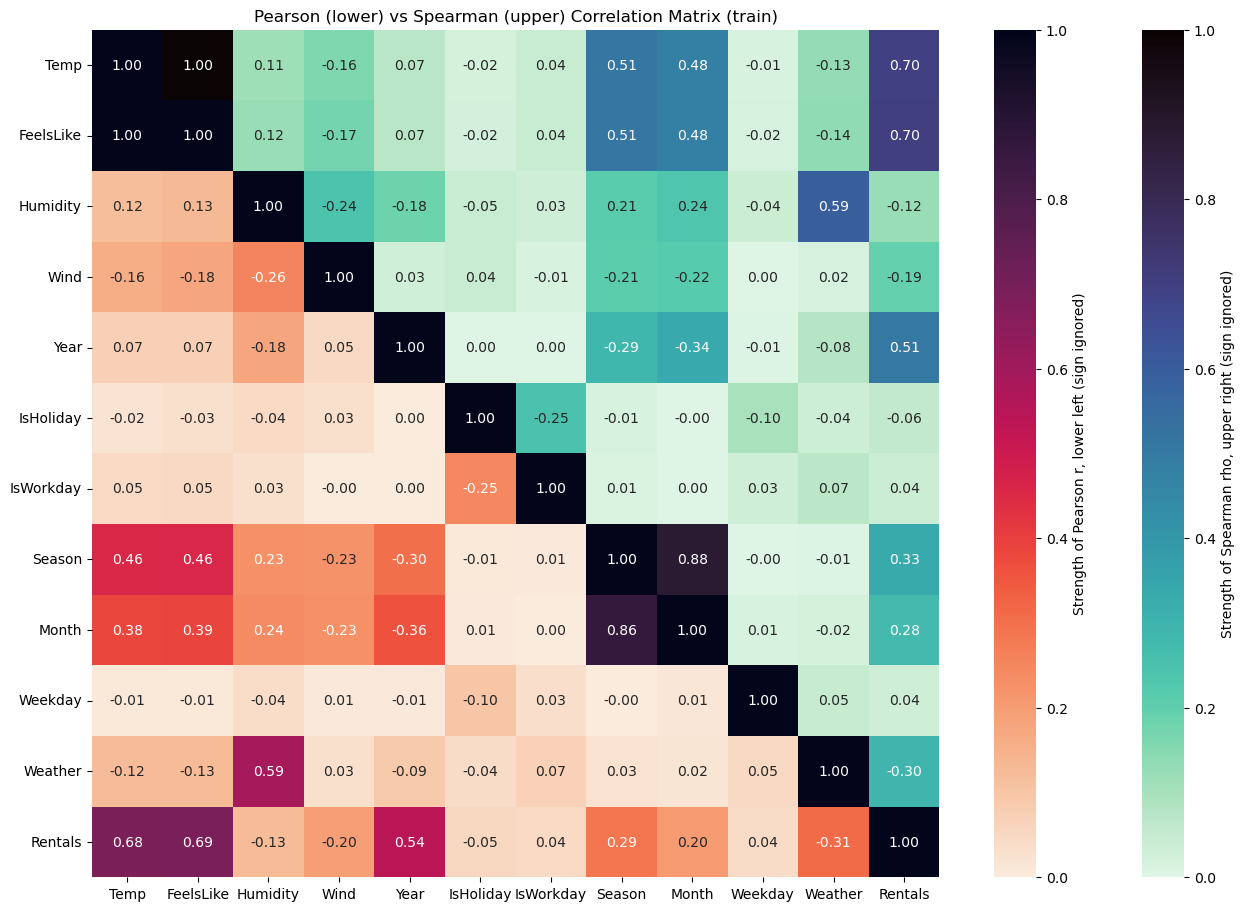

In [6]:
PLOTTING.correlation_matrix(
	pearson=train_df[ATTRIBUTES + [Q2_CONSTS.TARGET]].corr(),
	spearman=train_df[ATTRIBUTES + [Q2_CONSTS.TARGET]].corr(method='spearman'),
	title='Pearson (lower) vs Spearman (upper) Correlation Matrix (train)',
	figsize=(14, 9),
)

### Notes / Observations

- Three attributes lead with `Rentals`, all moderate: `FeelsLike`, `Temp` and `Year`, led by `FeelsLike` (0.69).
- `IsHoliday`, `IsWorkday` and `Weekday` show no linear relationship with `Rentals` (0.05 or less in size).
- Pearson and Spearman agree on the 4 continuous attributes (within 0.02), so ranking the values uncovers no stronger trend than the straight line. Neither coefficient shows the leveling off at the warm end seen in the scatter matrix.
- r on a code reads only a straight line across the code numbers: a code whose `Rentals` rise and then fall, or jump between levels, gets a small r even when its levels differ a lot. So the r of `Season`, `Month`, `Weekday` and `Weather` can understate their tie to `Rentals` (ex `Month`, r 0.20).
- Three pairs stand out: `Temp` / `FeelsLike` and `Season` / `Month` are strong, `Humidity` / `Weather` is moderate. Every other Pearson r is 0.46 or less in size.
- Calendar ties: `Season` and `Month` rise with `Temp` and `FeelsLike` (0.38 to 0.46), so the calendar and temperature carry part of the same information.
- `Year` falls with `Season` and `Month` because of where train stops (2012-08-06): the second year's train rows end in early August, so its later seasons and months are missing.

## Collinearity

> How To Read

- **Rows:** one per pair of attributes, sorted by the size of the r between them, largest first. `Rentals` never forms a pair.
- **r between attributes:** the Pearson r of the two attributes with each other. Near 1 or -1, the two move together, so a linear model has trouble splitting the credit between them.
- **r with target, first / second:** each attribute's Pearson r with `Rentals`, in the order the pair is named. In a strongly correlated pair, it shows which of the two tracks `Rentals` more closely.
- All 11 attributes are included. For `Season`, `Month`, `Weekday` and `Weather`, r reads only a straight line across the codes.
- **Filter:** only pairs with an r between attributes of 0.3 or more in size are shown (`COLLINEARITY_MIN_R`). Below 0.3 the two share less than 10% of their variation (r²), too little to matter for collinearity. The line above the table counts the pairs left out.

In [7]:
STATISTICS.collinearity_df(df=train_df[ATTRIBUTES + [Q2_CONSTS.TARGET]], target=Q2_CONSTS.TARGET, min_abs_r=COLLINEARITY_MIN_R)

9 of 55 pairs shown: the other 46 have |r between attributes| below 0.3.


,r between attributes,"r with target, first","r with target, second"
Temp + FeelsLike,0.997,0.685,0.690
Season + Month,0.862,0.289,0.205
Humidity + Weather,0.586,-0.128,-0.309
FeelsLike + Season,0.459,0.690,0.289
Temp + Season,0.456,0.685,0.289
FeelsLike + Month,0.390,0.690,0.205
Temp + Month,0.383,0.685,0.205
Year + Month,-0.361,0.540,0.205
Year + Season,-0.303,0.540,0.289


### R2 Gain

> How To Read

One row per pair of attributes. Each pair is an ordinary linear regression of `Rentals` on its two attributes, fit on the train rows.

- **r2 together:** the R² of the fit on both attributes of the pair.
- **r2 best with one left out:** the higher R² of the two fits on one attribute alone.
- **r2 gain:** r2 together minus r2 best with one left out, so what the weaker attribute adds on top of the other. Rows are sorted by it, largest first.
- A gain near 0 means the attribute's information is already in the other one, even when its own r with `Rentals` is high. A large gain means it brings information the other one lacks.
- Every R² is scored on the rows it is fit on, so a gain is never below 0 and is a little optimistic. A gain of a few thousandths is not evidence on its own.
- Only the 4 continuous and 3 binary attributes are included. `Season`, `Month`, `Weekday` and `Weather` are codes, and one column per code reads only a straight line across them (see the correlation notes).
- **Filter:** only pairs with a gain of 0.01 or more are shown (`R2_GAIN_MARGIN`, the same bar Q2B uses to draw a candidate shape). The line above the table counts the pairs left out, and a missing pair is one that adds less than 0.01.

In [8]:
STATISTICS.r2_gain_df(df=train_df[Q2_CONSTS.CONTINUOUS + BINARY + [Q2_CONSTS.TARGET]], target=Q2_CONSTS.TARGET, min_gain=R2_GAIN_MARGIN)  # pairs

6 of 21 pairs shown: the other 15 gain less than 0.01.


,r2 best with one left out,r2 together,r2 gain
Temp + Year,0.469,0.711,0.242
FeelsLike + Year,0.476,0.717,0.241
Wind + Year,0.292,0.342,0.050
FeelsLike + Humidity,0.476,0.524,0.048
Temp + Humidity,0.469,0.513,0.044
Humidity + Wind,0.039,0.072,0.034


### Notes / Observations

- Three pairs stand out: `Temp` + `FeelsLike`, `Season` + `Month` and `Humidity` + `Weather`, with the next pair at 0.459.
- Within these three pairs, the r with `Rentals` favors `FeelsLike` over `Temp` by a hair (0.690 against 0.685), and `Weather` over `Humidity` clearly.
- `Temp` and `FeelsLike` are interchangeable: their pair is left out for gaining less than 0.01.
- `Year` is the big addition: nearly unrelated to temperature in the correlation matrix, it adds +0.242 to `Temp` and about the same to `FeelsLike`, far more than any other pair.
- `Humidity` adds a little on top of temperature: +0.048 to `FeelsLike`, despite its weak r with `Rentals`.
- `Wind` adds less than 0.01 to temperature: both its pairs with `Temp` and `FeelsLike` are left out.
- `IsHoliday` and `IsWorkday` add nothing in any company: no pair they join reaches 0.01, so none is shown.